# Tutorial 12 (T12): Building Programs to Perform Cluster Evaluation

## 📌 Objective
Perform comprehensive evaluation of clustering algorithms using both **Internal Validation Metrics** (unsupervised, no true labels needed) and **External Validation Metrics** (supervised, comparing against ground-truth crop classes). Evaluate across multiple values of $k$ and compare **K-Means** against **Hierarchical Clustering**.

## 🔬 Key Evaluation Metrics & Formulas
1. **Silhouette Score ($s$)**: Measures intra-cluster cohesion vs nearest-cluster separation (Range: $[-1, +1]$, higher is better):
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
2. **Davies-Bouldin Index (DBI)**: Ratio of within-cluster scatter to between-cluster separation (Lower is better):
   $$DB = \frac{1}{k} \sum_{i=1}^k \max_{j \ne i} \left( \frac{\sigma_i + \sigma_j}{d(\mu_i, \mu_j)} \right)$$
3. **Calinski-Harabasz Index (Variance Ratio Criterion)**: Ratio of between-cluster dispersion to within-cluster dispersion (Higher is better):
   $$CH = \frac{\text{Tr}(B_k)}{\text{Tr}(W_k)} \times \frac{n - k}{k - 1}$$
4. **Adjusted Rand Index (ARI)**: Chance-corrected measure of agreement between cluster assignments and ground truth (Range: $[-1, +1]$, $1 =$ perfect match).

### Step 1: Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, normalized_mutual_info_score,
    homogeneity_score, completeness_score, v_measure_score
)

sns.set_theme(style="whitegrid", palette="muted")
print('Cluster evaluation libraries ready!')

Cluster evaluation libraries ready!


### Step 2: Load Data and Standardize

In [2]:
df = pd.read_csv('data/Crop_recommendation.csv')
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X = df[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

le = LabelEncoder()
y_true = le.fit_transform(df['label'])
print(f'Loaded {len(df)} samples across {len(le.classes_)} true crop classes.')

Loaded 2200 samples across 22 true crop classes.


### Step 3: Compute Internal Validation Metrics for $k \in [2, 8]$
We sweep $k$ from 2 to 8 and record Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index.

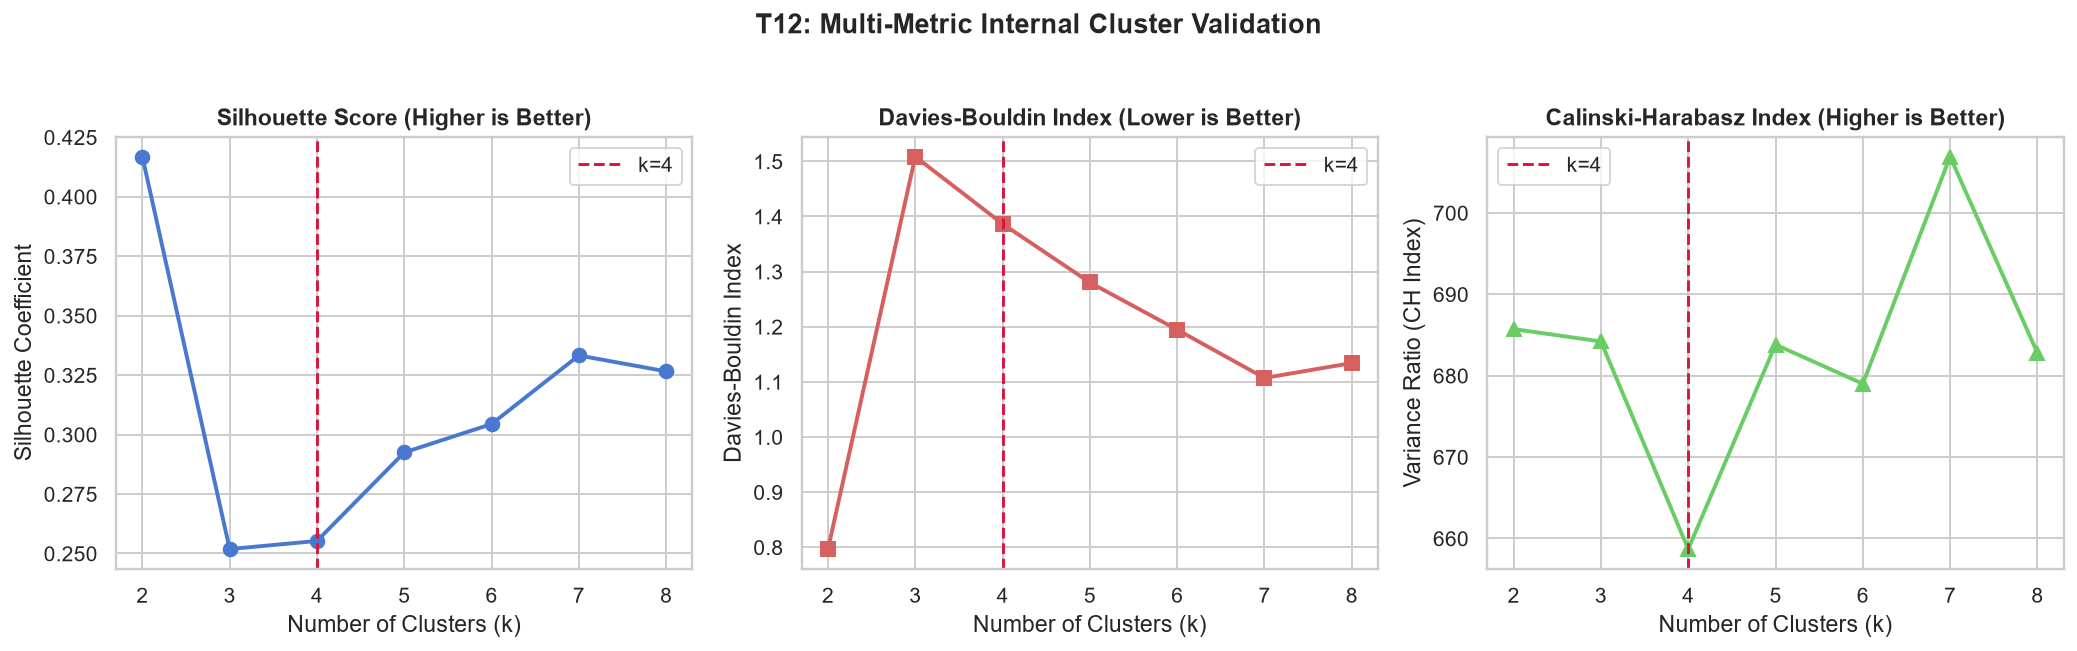

In [3]:
k_eval_range = range(2, 9)
sil_scores = []
db_scores = []
ch_scores = []

for k in k_eval_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))
    ch_scores.append(calinski_harabasz_score(X_scaled, labels))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.5), dpi=140)

# 1. Silhouette
ax1.plot(list(k_eval_range), sil_scores, 'bo-', linewidth=2, markersize=7)
ax1.set_title('Silhouette Score (Higher is Better)', fontweight='bold')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Silhouette Coefficient')
ax1.axvline(x=4, color='crimson', linestyle='--', label='k=4')
ax1.legend()

# 2. Davies-Bouldin
ax2.plot(list(k_eval_range), db_scores, 'rs-', linewidth=2, markersize=7)
ax2.set_title('Davies-Bouldin Index (Lower is Better)', fontweight='bold')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Davies-Bouldin Index')
ax2.axvline(x=4, color='crimson', linestyle='--', label='k=4')
ax2.legend()

# 3. Calinski-Harabasz
ax3.plot(list(k_eval_range), ch_scores, 'g^-', linewidth=2, markersize=7)
ax3.set_title('Calinski-Harabasz Index (Higher is Better)', fontweight='bold')
ax3.set_xlabel('Number of Clusters (k)')
ax3.set_ylabel('Variance Ratio (CH Index)')
ax3.axvline(x=4, color='crimson', linestyle='--', label='k=4')
ax3.legend()

plt.suptitle('T12: Multi-Metric Internal Cluster Validation', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### Step 4: Detailed Silhouette Sample Analysis for $k=4$
We generate a per-cluster silhouette plot showing the thickness and individual coefficient distribution for each of the 4 clusters.

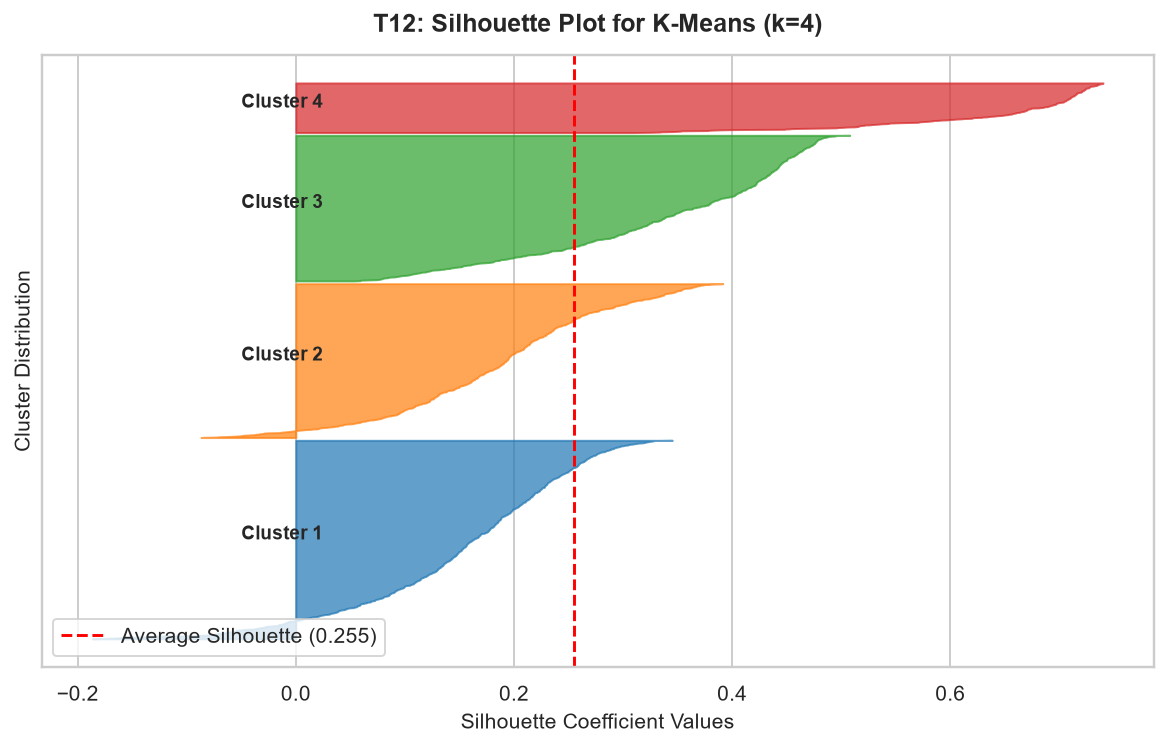

In [4]:
k_chosen = 4
km_final = KMeans(n_clusters=k_chosen, init='k-means++', n_init=10, random_state=42)
km_labels = km_final.fit_predict(X_scaled)
avg_sil = silhouette_score(X_scaled, km_labels)
sample_sil_values = silhouette_samples(X_scaled, km_labels)

fig, ax = plt.subplots(figsize=(8.5, 5.5), dpi=140)
y_lower = 10
palette = sns.color_palette('tab10', k_chosen)

for i in range(k_chosen):
    ith_cluster_sil = sample_sil_values[km_labels == i]
    ith_cluster_sil.sort()
    size_i = ith_cluster_sil.shape[0]
    y_upper = y_lower + size_i
    color = palette[i]
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil, facecolor=color, edgecolor=color, alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * size_i, f'Cluster {i+1}', fontsize=10, fontweight='bold')
    y_lower = y_upper + 10

ax.set_title('T12: Silhouette Plot for K-Means (k=4)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Silhouette Coefficient Values', fontsize=11)
ax.set_ylabel('Cluster Distribution', fontsize=11)
ax.axvline(x=avg_sil, color='red', linestyle='--', linewidth=1.5, label=f'Average Silhouette ({avg_sil:.3f})')
ax.set_yticks([])
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

### Step 5: Master Comparison: K-Means vs Hierarchical Clustering
We fit Agglomerative Clustering ($k=4$) and evaluate both algorithms side-by-side on all 8 internal and external validation metrics.

In [5]:
agg_final = AgglomerativeClustering(n_clusters=4, linkage='ward')
agg_labels = agg_final.fit_predict(X_scaled)

metrics_data = {
    'Evaluation Metric': [
        'Silhouette Score (Internal, ↑)',
        'Davies-Bouldin Index (Internal, ↓)',
        'Calinski-Harabasz Index (Internal, ↑)',
        'Adjusted Rand Index - ARI (External, ↑)',
        'Normalized Mutual Info - NMI (External, ↑)',
        'Homogeneity Score (External, ↑)',
        'Completeness Score (External, ↑)',
        'V-Measure Score (External, ↑)'
    ],
    'K-Means (k=4)': [
        round(silhouette_score(X_scaled, km_labels), 4),
        round(davies_bouldin_score(X_scaled, km_labels), 4),
        round(calinski_harabasz_score(X_scaled, km_labels), 2),
        round(adjusted_rand_score(y_true, km_labels), 4),
        round(normalized_mutual_info_score(y_true, km_labels), 4),
        round(homogeneity_score(y_true, km_labels), 4),
        round(completeness_score(y_true, km_labels), 4),
        round(v_measure_score(y_true, km_labels), 4)
    ],
    'Hierarchical Ward (k=4)': [
        round(silhouette_score(X_scaled, agg_labels), 4),
        round(davies_bouldin_score(X_scaled, agg_labels), 4),
        round(calinski_harabasz_score(X_scaled, agg_labels), 2),
        round(adjusted_rand_score(y_true, agg_labels), 4),
        round(normalized_mutual_info_score(y_true, agg_labels), 4),
        round(homogeneity_score(y_true, agg_labels), 4),
        round(completeness_score(y_true, agg_labels), 4),
        round(v_measure_score(y_true, agg_labels), 4)
    ]
}
df_compare = pd.DataFrame(metrics_data)
print('=== Comprehensive Clustering Evaluation Benchmark ===')
display(df_compare)

,Evaluation Metric,K-Means (k=4),Hierarchical Ward (k=4)
0,"Silhouette Score (Internal, ↑)",0.2553,0.2592
1,"Davies-Bouldin Index (Internal, ↓)",1.3866,1.4269
2,"Calinski-Harabasz Index (Internal, ↑)",658.7000,629.4700
3,"Adjusted Rand Index - ARI (External, ↑)",0.1856,0.1411
4,"Normalized Mutual Info - NMI (External, ↑)",0.5373,0.5082
5,"Homogeneity Score (External, ↑)",0.3812,0.3498
6,"Completeness Score (External, ↑)",0.9101,0.9288
7,"V-Measure Score (External, ↑)",0.5373,0.5082


=== Comprehensive Clustering Evaluation Benchmark ===


### 🎓 Viva Voce Questions & Answers (Tutorial 12)

1. **Q: What does a negative Silhouette score indicate?**
   - **A:** A negative silhouette score means that $a(i) > b(i)$, which indicates that a sample is closer to points in a neighboring cluster than to points in its own assigned cluster. It signifies misclustering or boundary overlap.

2. **Q: What is the difference between Homogeneity and Completeness?**
   - **A:** **Homogeneity** measures whether each cluster contains only members of a single class. **Completeness** measures whether all members of a given class are assigned to the same cluster. Their harmonic mean is the **V-Measure**.

3. **Q: Why is Adjusted Rand Index (ARI) preferred over raw Rand Index?**
   - **A:** The raw Rand Index does not account for chance agreements; random clustering can score well above 0. ARI adjusts for chance so that a random assignment scores near 0.0, and perfect clustering scores 1.0.